# The enhanced search vs plain alpha-beta (the v4 engine)

## Goal

Measure the v4 engine's search — `search.search_alpha_beta_with_quiescence`
(connect6/search.py): plain alpha-beta plus quiescence and forward pruning
(docs/EVALUATION.md, section 10) — against the plain `search.search_alpha_beta` (v3) it
extends, exactly as the evaluation chapter reports it:

- **Position tables** — nodes, wall time, score and move on the five documented positions
  at depths 2-4 (depths 1-3 for the completed-fork defence): the verdict columns, where
  quiescence finds the proven-win or proven-loss score while plain alpha-beta still
  oscillates in the unproven middle of the scale, and the cost columns, where the pruning
  shrinks the depth-4 trees.
- **Head-to-head games** — the section-10 referee protocol: depth 3, twelve games over six
  openings (white's first reply varied), color assignments alternated per game, played
  one worker process per game through `harness.run_games`.
- **A common trajectory** — one deterministic v4-vs-v4 game (center opening, white's first
  reply IIKK, depth 3, 48-ply cap); every decision point of that game re-analyzed by both
  searches at the deployment depth, one worker per position through
  `harness.analyze_history`. The same trajectory serves the v5 notebook's v4-vs-v5
  measurement.
- **The declined enhancement, measured** — a replica of the plain search, asserted
  node-identical to the package, instrumented to count transpositions, with a sound
  transposition table on top: the section-10.4 rejection, numbers on record.

Weights are pinned to `tuning/winner.json`, the shipped tuned weight set — the exact configuration
the documentation measures. The searches are deterministic, so every node count, score and
move below reproduces docs/EVALUATION.md, section 10.2 exactly; only the wall-time column
varies between runs. The validation cells assert all of it — a clean run of this notebook
is a validation of the section-10 tables.

## Expected behaviour

The enhanced search must (1) find the fork-attack win a full depth earlier than plain
(depth 2 vs depth 3, 32 nodes vs 173), (2) score the completed-fork defence correctly from
depth 1, (3) get the five-run verdict right at every depth where plain oscillates
10,460 → 1,536 → 11,596, and (4) roughly halve the depth-4 trees on quiet (non-tactical)
positions (15,964 → 7,581 opening, 11,799 → 3,782 midgame). In the head-to-head fixture the shipped
configuration wins 11 of 12. On the common trajectory the enhancement changes 27 of 48
moves without one verdict-band flip, at 3.8x plain's mean nodes (6,667 vs 1,762). The
sound transposition table recovers the full revisit bound at depth 3 — 3.0-14.6% of nodes —
and still yields no reliable wall-time improvement.

Runtime: about 6 minutes (the trajectory self-play dominates; the games, the position
analyses and the replicas run in parallel or cost seconds).



In [1]:
import os
import sys
import time
from collections import Counter
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
sys.path.insert(0, str(ROOT / "tuning"))

import harness
from connect6.board import copy_board, is_board_empty, make_move, opponent, unmake_move
from connect6.candidates import generate_candidate_moves
from connect6.defines import GRID_NUM, MAXINT, MININT, MAX_CANDIDATE_MOVES, Color, Move, Position, SearchStats, SearchResult
from connect6.evaluation import evaluate
from connect6.protocol import move2msg
from connect6.search import search_alpha_beta, search_alpha_beta_with_quiescence

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")


weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)


## Position tables

The five positions come from `tuning/harness.py` (`documented_positions`) — the same boards
behind the section-10 and section-11 tables. `win verdict` marks a score in the terminal
band (±20,000). Watch the three verdict positions: plain alpha-beta needs depth 3 for the
fork attack and never gets the five-run right at depths 2-4; enhanced is exact at every
depth. Watch the two quiet (non-tactical) positions at depth 4: the pruning repays the extra
cost of the quiescence extension.

In [2]:
DEPTH_PLAN = {
    "opening scatter, white to move": (2, 3, 4),
    "midgame, white to move": (2, 3, 4),
    "fork attack, black to move": (2, 3, 4),
    "fork completed, white to move": (1, 2, 3),
    "five-run attack, white to move": (2, 3, 4),
}

table_rows = {}
for label, board, color, pre_move in harness.documented_positions():
    depths = DEPTH_PLAN.get(label)
    if depths is None:
        continue
    print(f"== {label} ==")
    print(f"{'method':9s} {'depth':5s} {'nodes':>7s} {'ms':>8s} {'score':>7s}  move")
    for depth in depths:
        for name, search in (("plain", search_alpha_beta), ("enhanced", search_alpha_beta_with_quiescence)):
            stats = SearchStats()
            start = time.perf_counter()
            result = search(board, color, depth, pre_move, stats)
            elapsed = (time.perf_counter() - start) * 1000
            marker = " <- win verdict" if result.score in (MAXINT, -MAXINT) else ""
            print(f"{name:9s} {depth:5d} {stats.node_count:7d} {elapsed:8.1f} {result.score:7d}  {move2msg(result.move)}{marker}")
            table_rows[(label, name, depth)] = (stats.node_count, result.score, move2msg(result.move))
    print()

== opening scatter, white to move ==
method    depth   nodes       ms   score  move
plain         2     164     23.8     -40  CIIP
enhanced      2     164     46.9     -40  CIIP


plain         3    1593    178.5    -436  CIIP


enhanced      3    1668    596.8    -386  CKJP


plain         4   15964   4321.0     -40  CKJP


enhanced      4    7581   4404.7     -38  CKJP

== midgame, white to move ==
method    depth   nodes       ms   score  move
plain         2     191     49.5    -134  FJII


...

enhanced      4    3782   3026.5    -617  JGII

== fork attack, black to move ==
method    depth   nodes       ms   score  move
plain         2     173     40.4     742  FJJN
enhanced      2      32     34.4   20000  JNBJ <- win verdict
plain         3      78     39.3   20000  JNBJ <- win verdict
enhanced      3      78     55.0   20000  JNBJ <- win verdict


plain         4     347    106.9   20000  JNBJ <- win verdict
enhanced      4     179    109.2   20000  JNBJ <- win verdict

== fork completed, white to move ==
method    depth   nodes       ms   score  move
plain         1      31      4.7     742  JMFE
enhanced      1      31     46.7   20000  GJHJ <- win verdict
plain         2      77     45.5   20000  GJHJ <- win verdict


enhanced      2      77     69.1   20000  GJHJ <- win verdict
plain         3     347     95.4   20000  GJHJ <- win verdict


enhanced      3     207    227.7   20000  GJHJ <- win verdict

== five-run attack, white to move ==
method    depth   nodes       ms   score  move
plain         2      90     20.1   10460  HJBJ
enhanced      2      87     51.6   20000  HJBJ <- win verdict
plain         3     249     68.8    1536  HJBJ
enhanced      3     103     59.1   20000  HJBJ <- win verdict


plain         4    1616    367.7   11596  HJBJ
enhanced      4     110     54.9   20000  HJBJ <- win verdict



## Validation

The cell below re-checks every measured row against the documented table — the deterministic
fields only: nodes, score, move. Wall time is measured, not asserted.

In [3]:
EXPECTED_ROWS = {
    ("opening scatter, white to move", "plain", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", "enhanced", 2): (164, -40, "CIIP"),
    ("opening scatter, white to move", "plain", 3): (1593, -436, "CIIP"),
    ("opening scatter, white to move", "enhanced", 3): (1668, -386, "CKJP"),
    ("opening scatter, white to move", "plain", 4): (15964, -40, "CKJP"),
    ("opening scatter, white to move", "enhanced", 4): (7581, -38, "CKJP"),
    ("midgame, white to move", "plain", 2): (191, -134, "FJII"),
    ("midgame, white to move", "enhanced", 2): (402, -134, "FJII"),
    ("midgame, white to move", "plain", 3): (1425, -2342, "FJII"),
    ("midgame, white to move", "enhanced", 3): (1458, -703, "BJII"),
    ("midgame, white to move", "plain", 4): (11799, -305, "FJKI"),
    ("midgame, white to move", "enhanced", 4): (3782, -617, "JGII"),
    ("fork attack, black to move", "plain", 2): (173, 742, "FJJN"),
    ("fork attack, black to move", "enhanced", 2): (32, 20000, "JNBJ"),
    ("fork attack, black to move", "plain", 3): (78, 20000, "JNBJ"),
    ("fork attack, black to move", "enhanced", 3): (78, 20000, "JNBJ"),
    ("fork attack, black to move", "plain", 4): (347, 20000, "JNBJ"),
    ("fork attack, black to move", "enhanced", 4): (179, 20000, "JNBJ"),
    ("fork completed, white to move", "plain", 1): (31, 742, "JMFE"),
    ("fork completed, white to move", "enhanced", 1): (31, 20000, "GJHJ"),
    ("fork completed, white to move", "plain", 2): (77, 20000, "GJHJ"),
    ("fork completed, white to move", "enhanced", 2): (77, 20000, "GJHJ"),
    ("fork completed, white to move", "plain", 3): (347, 20000, "GJHJ"),
    ("fork completed, white to move", "enhanced", 3): (207, 20000, "GJHJ"),
    ("five-run attack, white to move", "plain", 2): (90, 10460, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 2): (87, 20000, "HJBJ"),
    ("five-run attack, white to move", "plain", 3): (249, 1536, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 3): (103, 20000, "HJBJ"),
    ("five-run attack, white to move", "plain", 4): (1616, 11596, "HJBJ"),
    ("five-run attack, white to move", "enhanced", 4): (110, 20000, "HJBJ"),
}

for key, expected in EXPECTED_ROWS.items():
    measured = table_rows[key]
    assert measured == expected, f"{key}: measured {measured}, documented {expected}"
print(f"all {len(EXPECTED_ROWS)} position rows reproduce section 10.2 exactly (nodes, score, move)")

all 30 position rows reproduce section 10.2 exactly (nodes, score, move)


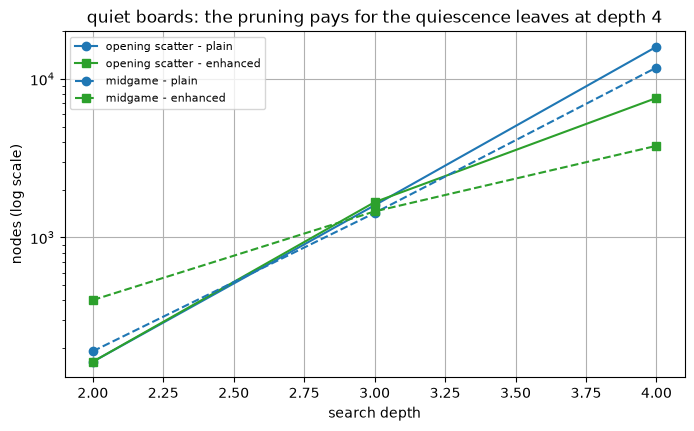

In [4]:
import matplotlib.pyplot as plt

quiet = ("opening scatter, white to move", "midgame, white to move")
fig, ax = plt.subplots(figsize=(8, 4.5))
styles = {quiet[0]: "-", quiet[1]: "--"}
for label in quiet:
    for name, color in (("plain", "tab:blue"), ("enhanced", "tab:green")):
        depths = DEPTH_PLAN[label]
        nodes = [table_rows[(label, name, d)][0] for d in depths]
        ax.plot(depths, nodes, marker="o" if name == "plain" else "s", color=color,
                linestyle=styles[label], label=f"{label.split(',')[0]} - {name}")
ax.set_yscale("log")
ax.set_xlabel("search depth")
ax.set_ylabel("nodes (log scale)")
ax.set_title("quiet boards: the pruning pays for the quiescence leaves at depth 4")
ax.grid(True)
ax.legend(fontsize=8)
plt.show()

## Head-to-head at the deployment depth

Both searches through the real referee (`harness.play_game`): center opening, white's first
reply forced to the six seeded openings, depth 3, 60-ply cap, the shipped tuned weight set
for both sides — the engines differ only in the search method. Deterministic engines, so
the twelve games are the complete fixture, not a sample. The games share nothing, so they
run one worker process each (`harness.run_games`); the records are bit-identical to
sequential play. The shipped configuration's documented record is 11-1 (section 10.2), the
lone loss one color assignment of one opening.


In [5]:
SEEDS = ["IIKK", "JIKJ", "JKJI", "IKKJ", "LLHH", "HHGG"]
GAMES = 2 * len(SEEDS)

plans = []
for game in range(GAMES):
    seed = SEEDS[game % len(SEEDS)]
    enhanced_is_black = (game // len(SEEDS)) % 2 == 0
    black = harness.PlayerSpec(search_alpha_beta_with_quiescence if enhanced_is_black else search_alpha_beta)
    white = harness.PlayerSpec(search_alpha_beta if enhanced_is_black else search_alpha_beta_with_quiescence)
    plans.append((seed, enhanced_is_black, harness.GameSpec(black, white, 3, 60, seed)))

start = time.perf_counter()
records = harness.run_games([plan[2] for plan in plans])
print(f"== head-to-head at depth 3 (enhanced vs plain, {GAMES} games over {len(SEEDS)} openings, "
      f"{time.perf_counter() - start:.0f} s across twelve workers) ==")
games = []
for (seed, enhanced_is_black, _), record in zip(plans, records):
    if record.winner is None:
        outcome = "draw"
    else:
        enhanced_won = record.winner == (Color.BLACK if enhanced_is_black else Color.WHITE)
        outcome = "enhanced" if enhanced_won else "plain"
    stones = sum(1 for x in range(1, GRID_NUM - 1) for y in range(1, GRID_NUM - 1) if record.board[x][y] != 0)
    games.append((seed, enhanced_is_black, outcome, stones))
    enhanced_tally = record.black if enhanced_is_black else record.white
    plain_tally = record.white if enhanced_is_black else record.black
    print(f"game {len(games):2d}: opening {seed}, enhanced as {'black' if enhanced_is_black else 'white'}: "
          f"{outcome:9s} {stones} stones | enhanced {enhanced_tally.nodes:,} nodes, "
          f"{enhanced_tally.ms / max(enhanced_tally.moves, 1):.0f} ms/move | "
          f"plain {plain_tally.nodes:,} nodes, {plain_tally.ms / max(plain_tally.moves, 1):.0f} ms/move")


== head-to-head at depth 3 (enhanced vs plain, 12 games over 6 openings, 170 s across twelve workers) ==
game  1: opening IIKK, enhanced as black: enhanced  81 stones | enhanced 52,552 nodes, 3062 ms/move | plain 31,770 nodes, 776 ms/move
game  2: opening JIKJ, enhanced as black: enhanced  53 stones | enhanced 76,114 nodes, 6443 ms/move | plain 25,835 nodes, 738 ms/move
game  3: opening JKJI, enhanced as black: enhanced  97 stones | enhanced 136,378 nodes, 5334 ms/move | plain 40,495 nodes, 572 ms/move
game  4: opening IKKJ, enhanced as black: enhanced  41 stones | enhanced 37,773 nodes, 4211 ms/move | plain 17,618 nodes, 760 ms/move
game  5: opening LLHH, enhanced as black: enhanced  29 stones | enhanced 32,853 nodes, 4897 ms/move | plain 7,512 nodes, 427 ms/move
game  6: opening HHGG, enhanced as black: enhanced  29 stones | enhanced 11,416 nodes, 1840 ms/move | plain 6,905 nodes, 393 ms/move
game  7: opening IIKK, enhanced as white: enhanced  39 stones | enhanced 18,297 nodes, 2229 

In [6]:
outcomes = [outcome for _, _, outcome, _ in games]
assert outcomes.count("enhanced") == 11, f"wins: {outcomes.count('enhanced')}"
assert outcomes.count("plain") == 1, f"losses: {outcomes.count('plain')}"
assert outcomes.count("draw") == 0
stones = [s for *_, s in games]
assert 25 <= min(stones) and max(stones) <= 97
print("head-to-head record reproduces section 10.2: enhanced wins 11-1 of 12, 25-97 stones")

head-to-head record reproduces section 10.2: enhanced wins 11-1 of 12, 25-97 stones


## A common trajectory: v4 against v3, move by move

One deterministic game — the enhanced search against itself, center opening, white's first
reply IIKK, depth 3, capped at 48 plies — then every decision point of the recorded game
re-analyzed by both searches at the deployment depth through `harness.analyze_history` (one
worker process per position and search). The recorded game is pinned move-for-move below,
so the trajectory is the exact one the v5 notebook re-measures against `search_v5`. Node
counts, scores and moves are exact and asserted; wall seconds under twelve-way load are
indicative only, so the record is nodes.


The game is stored as `benchmarks/trajectory.json` — the prepared trajectory the later
notebooks load — and this notebook, which generates the game, verifies the stored copy
against a fresh generation on every run.

In [7]:
EXPECTED_HISTORY = 'JJ IIKK JKLJ KJKI KLJI JLIJ JHLH JGIH KHLI LKIG IKIF LGHG KGKF KEJF HHMJ MHNK GGLF MEML NMLM MNLE JENE MKLD OKMC MMNJ MOHK LLOI KMPH NLNI NHNN GKHI GJOM OJPL OLPK ONLN PIIL FIKN GIHL GHHJ GMQJ FNRI FGHM FLKO EMJP FMGN PJLP KQPG FOIM JMHO INEL'.split()

enhanced_player = harness.search_player(search_alpha_beta_with_quiescence)
trajectory = harness.play_game(enhanced_player, enhanced_player, 3, white_first_reply="IIKK", max_plies=48)
history = ["JJ"] + trajectory.moves
assert history == EXPECTED_HISTORY
assert trajectory.winner is None and trajectory.plies == 48
assert (trajectory.black.nodes, trajectory.white.nodes) == (144203, 173211)
import json

fixture = json.loads((ROOT / "benchmarks" / "trajectory.json").read_text())
assert history == fixture["history"]
print(f"trajectory: 48-ply v4 self-play, no win inside the cap, "
      f"black {trajectory.black.nodes:,} / white {trajectory.white.nodes:,} nodes to generate it; "
      f"fixture identity: benchmarks/trajectory.json (move-for-move)")

rows = harness.analyze_history(history, [("v3", search_alpha_beta), ("v4", search_alpha_beta_with_quiescence)], 3)
per_prefix = {}
for row in rows:
    per_prefix.setdefault(row.prefix, {})[row.name] = row
positions = sorted(per_prefix)
n = len(positions)

totals = {name: sum(per_prefix[p][name].nodes for p in positions) for name in ("v3", "v4")}
changes = sum(1 for p in positions if per_prefix[p]["v3"].move != per_prefix[p]["v4"].move)
flips = sum(1 for p in positions if (abs(per_prefix[p]["v3"].score) >= 20000) != (abs(per_prefix[p]["v4"].score) >= 20000))
peak = max(positions, key=lambda p: per_prefix[p]["v4"].nodes)
print(f"{'engine':6s} {'total nodes':>12s} {'mean/position':>13s} {'peak':>8s}")
for name in ("v3", "v4"):
    top = max(per_prefix[p][name].nodes for p in positions)
    print(f"{name:6s} {totals[name]:12,d} {totals[name] // n:13,d} {top:8,d}")
print(f"move changes: {changes}/{n}   verdict-band flips: {flips}/{n}   v4 node peak: prefix {peak}")

trajectory: 48-ply v4 self-play, no win inside the cap, black 144,203 / white 173,211 nodes to generate it; fixture identity: benchmarks/trajectory.json (move-for-move)


engine  total nodes mean/position     peak
v3           84,596         1,762    3,847
v4          320,038         6,667   40,262
move changes: 27/48   verdict-band flips: 0/48   v4 node peak: prefix 40


In [8]:
EXPECTED_TRAJECTORY = {"v3_nodes": 84596, "v4_nodes": 320038, "changes": 27, "flips": 0, "v4_peak": 40262}
assert totals["v3"] == EXPECTED_TRAJECTORY["v3_nodes"]
assert totals["v4"] == EXPECTED_TRAJECTORY["v4_nodes"]
assert changes == EXPECTED_TRAJECTORY["changes"]
assert flips == EXPECTED_TRAJECTORY["flips"]
assert max(per_prefix[p]["v4"].nodes for p in positions) == EXPECTED_TRAJECTORY["v4_peak"]
print("trajectory rows reproduce section 10.2 exactly (nodes, move changes, verdict flips)")


trajectory rows reproduce section 10.2 exactly (nodes, move changes, verdict flips)


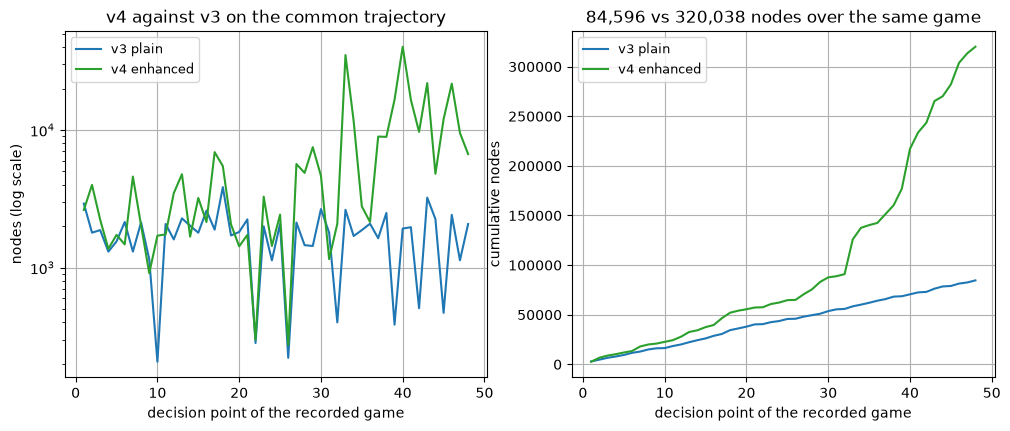

In [9]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v3"].nodes for p in positions], color="tab:blue", label="v3 plain")
ax.plot(positions, [per_prefix[p]["v4"].nodes for p in positions], color="tab:green", label="v4 enhanced")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("nodes (log scale)")
ax.set_title("v4 against v3 on the common trajectory")
ax.grid(True)
ax.legend(fontsize=9)
ax2.plot(positions, [sum(per_prefix[q]["v3"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:blue", label="v3 plain")
ax2.plot(positions, [sum(per_prefix[q]["v4"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:green", label="v4 enhanced")
ax2.set_xlabel("decision point of the recorded game")
ax2.set_ylabel("cumulative nodes")
ax2.set_title("84,596 vs 320,038 nodes over the same game")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()


## The declined enhancement: transposition tables, measured

Section 10.4 declines the classic fourth enhancement on measured grounds; this section is
that measurement. A replica of the plain search — same loop, same candidate order, same
cutoffs — is asserted node-identical to the package on every configuration below, then
instrumented twice: a revisit counter (how many visited positions repeat — the perfect-table
bound) and a sound transposition table on top (bound types exact/lower/upper,
depth-conditioned reuse, stored stand-pats). The key is the cheapest sound one — the board
as nested tuples — so the upkeep measured here is the floor of what a production table
would pay.


In [10]:
EXACT, LOWER, UPPER = 0, 1, 2


def position_key(board):
    return tuple(map(tuple, board))


def replica_ab(depth, board, color, pre_move, stats, alpha, beta, table=None, seen=None, hits=None):
    key = None
    if table is not None:
        key = (position_key(board), color)
        entry = table.get(key)
        if entry is not None and entry[0] >= depth:
            if hits is not None:
                hits[0] += 1
            flag, val, mv = entry[1]
            if flag == EXACT:
                return SearchResult(mv, val)
            if flag == LOWER and val >= beta:
                return SearchResult(mv, val)
            if flag == UPPER and val <= alpha:
                return SearchResult(mv, val)
    stats.node_count += 1
    if seen is not None:
        seen[(position_key(board), color)] += 1
    score = evaluate(board, pre_move)
    if score == MAXINT or score == MININT:
        if table is not None:
            table[key] = (depth, (EXACT, score, pre_move))
        return SearchResult(pre_move, score)
    if depth <= 0:
        if table is not None:
            table[key] = (depth, (EXACT, score, pre_move))
        return SearchResult(pre_move, score)
    candidates = generate_candidate_moves(board, MAX_CANDIDATE_MOVES, color)
    if len(candidates) == 0:
        if table is not None:
            table[key] = (depth, (EXACT, score, pre_move))
        return SearchResult(pre_move, score)
    maximizing = color == Color.BLACK
    best_score = MININT if maximizing else MAXINT
    best_move = candidates[0]
    a0, b0 = alpha, beta
    for candidate in candidates:
        make_move(board, candidate, color)
        child = replica_ab(depth - 1, board, opponent(color), candidate, stats, alpha, beta, table, seen, hits)
        unmake_move(board, candidate)
        if maximizing:
            if child.score > best_score:
                best_score, best_move = child.score, candidate
            if best_score >= beta:
                break
            if best_score > alpha:
                alpha = best_score
        else:
            if child.score < best_score:
                best_score, best_move = child.score, candidate
            if best_score <= alpha:
                break
            if best_score < beta:
                beta = best_score
    if table is not None:
        flag = UPPER if best_score <= a0 else (LOWER if best_score >= b0 else EXACT)
        table[key] = (depth, (flag, best_score, best_move))
    return SearchResult(best_move, best_score)


def replica(board, color, depth, pre_move, stats, table=None, seen=None, hits=None):
    working = copy_board(board)
    if is_board_empty(working):
        return SearchResult(Move((Position(10, 10), Position(10, 10))), 0)
    return replica_ab(depth, working, color, pre_move, stats, MININT, MAXINT, table, seen, hits)


tt_positions = [p for p in harness.documented_positions() if p[0].split(",")[0] in ("opening scatter", "midgame", "five-run attack")]
print("replica and sound table ready")


replica and sound table ready


In [11]:
EXPECTED_TT = {
    ("opening scatter, white to move", 3): (1593, 1545, 48, 48),
    ("opening scatter, white to move", 4): (15964, 15169, 658, 796),
    ("midgame, white to move", 3): (1425, 1217, 208, 208),
    ("midgame, white to move", 4): (11799, 10313, 1061, 1487),
    ("five-run attack, white to move", 3): (249, 249, 0, 0),
    ("five-run attack, white to move", 4): (1616, 1451, 165, 165),
}

print(f"{'position':28s} {'d':2s} {'nodes':>7s} {'TT nodes':>8s} {'saved':>6s} {'hits':>5s} {'revisits':>8s} {'TT ms':>6s} {'plain ms':>8s}")
for label, board, color, pre_move in tt_positions:
    for depth in (3, 4):
        plain_stats = SearchStats()
        start = time.perf_counter()
        plain = search_alpha_beta(board, color, depth, pre_move, plain_stats)
        plain_ms = (time.perf_counter() - start) * 1000
        replica_stats = SearchStats()
        result = replica(board, color, depth, pre_move, replica_stats)
        assert (replica_stats.node_count, result.score, result.move) == (plain_stats.node_count, plain.score, plain.move)
        seen = Counter()
        bound_stats = SearchStats()
        replica(board, color, depth, pre_move, bound_stats, seen=seen)
        revisits = bound_stats.node_count - len(seen)
        table = {}
        hits = [0]
        tt_stats = SearchStats()
        start = time.perf_counter()
        tt = replica(board, color, depth, pre_move, tt_stats, table=table, hits=hits)
        tt_ms = (time.perf_counter() - start) * 1000
        assert tt.score == plain.score and tt.move == plain.move
        assert EXPECTED_TT[(label, depth)] == (replica_stats.node_count, tt_stats.node_count, hits[0], revisits)
        saved = 100 * (replica_stats.node_count - tt_stats.node_count) / replica_stats.node_count
        print(f"{label:28s} {depth:2d} {replica_stats.node_count:7,d} {tt_stats.node_count:8,d} {saved:5.1f}% {hits[0]:5d} {revisits:8,d} {tt_ms:6.0f} {plain_ms:8.0f}")

def us_per_call(fn, n=20000):
    start = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - start) / n * 1e6

board, color, pre_move = tt_positions[1][1], tt_positions[1][2], tt_positions[1][3]
key = (position_key(board), Color.BLACK)
print(f"\nupkeep floor: position_key {us_per_call(lambda: position_key(board)):.1f} us, "
      f"dict probe {us_per_call(lambda: table.get(key)):.2f} us — against "
      f"evaluate {us_per_call(lambda: evaluate(board, pre_move)):.1f} us per node")
print("the recovered 3.0-14.6% of nodes buy a wall-clock wash: -7% to +2% across the six rows")


position                     d    nodes TT nodes  saved  hits revisits  TT ms plain ms


opening scatter, white to move  3   1,593    1,545   3.0%    48       48    144      142


opening scatter, white to move  4  15,964   15,169   5.0%   658      796   2390     2320


midgame, white to move        3   1,425    1,217  14.6%   208      208    187      194


midgame, white to move        4  11,799   10,313  12.6%  1061    1,487   1858     1935
five-run attack, white to move  3     249      249   0.0%     0        0     38       37


five-run attack, white to move  4   1,616    1,451  10.2%   165      165    201      193



upkeep floor: position_key 1.3 us, dict probe 0.03 us — against evaluate 42.3 us per node
the recovered 3.0-14.6% of nodes buy a wall-clock wash: -7% to +2% across the six rows


## Reading the results

- **Quiescence changes verdicts, not just moves** — the five-run defence is played by every
  search at every depth, but only the enhanced search ever calls it what it is: lost. Score
  and move decouple exactly as section 10.3 describes.
- **The extension horizon is real but bounded** — the fork attack is found one full depth
  earlier than plain; the six-ply extension fits the five-run chain exactly (fork, block,
  fork, block, unblockable fork, complete).
- **The pruning pays off at depth 4** — at depth 3 enhanced costs more wall time on
  quiet (non-tactical) boards (each quiescence extension generates extra candidate
  moves); at depth 4 it visits half the nodes. The deployment depth 3 is the worst case for the enhancement's economics and still
  the right trade for a tactical game.
- **On a real game the enhancement changes moves, not verdicts** — 27 of 48 trajectory
  decisions differ from plain's, and not one verdict band flips: the terminal-band verdict
  changes live in the curated positions, while a full quiet-to-sharp game spends 3.8x
  plain's mean nodes (6,667 vs 1,762) for its sharper move choices.
- **The transposition table is declined on the record** — the sound table recovers the full
  revisit bound at depth 3 (3.0-14.6% of nodes) and two-thirds of it at depth 4, and the
  wall clock still does not move (-7% to +2% over the six configurations): one key, one
  probe and one store per node eat exactly what the skipped nodes save, before the
  correctness burden of section 10.4 accounts for the rest of the rejection. Symmetries stay prose: the book
  already answers the symmetric prefix (10.4).
- **The head-to-head record is protocol-relative** — center opening, depth 3, six openings:
  the same caveat sections 9 and 10 carry. Full discussion: docs/EVALUATION.md, sections
  10.3 and 10.5.
